In [5]:
from google.colab import drive,files
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
dir="/content/drive/MyDrive/garbage_dataset"
print(os.listdir(dir))

['trash', 'paper', 'plastic', 'metal', 'cardboard', 'biological', 'glass']


In [7]:
import tensorflow as tf

IMG_SIZE=(224,224)
Batch=32
train_ds=tf.keras.utils.image_dataset_from_directory(
    dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=Batch
)

val_ds=tf.keras.utils.image_dataset_from_directory(
    dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=Batch
)
class_names=train_ds.class_names
print("Number of Classes: ",len(class_names))
print("Class Names: ",class_names)


Found 5759 files belonging to 7 classes.
Using 4608 files for training.
Found 5759 files belonging to 7 classes.
Using 1151 files for validation.
Number of Classes:  7
Class Names:  ['biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [8]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers,models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
print("TensorFlow Version: ",tf.__version__)
print("GPU Available: ",len(tf.config.list_physical_devices('GPU'))>0)

TensorFlow Version:  2.20.0
GPU Available:  True


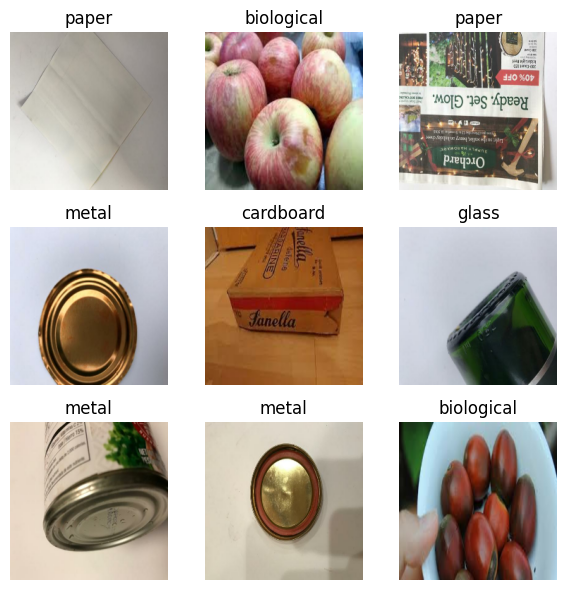

In [9]:
plt.figure(figsize=(6,6))
for images,labels in train_ds.take(1):
  num_images=min(9,len(images))
  for i in range(num_images):
    ax=plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [10]:
base_model=MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable=False
print("MobileNetV2 Loaded Successfully")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 Loaded Successfully


In [11]:
data_augmentation=models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])
inputs=layers.Input(shape=(224,224,3))
x=data_augmentation(inputs)
x=layers.Lambda(preprocess_input)(x)
x=base_model(x,training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.3)(x)

outputs=layers.Dense(len(class_names),activation="softmax")(x)
model=models.Model(inputs,outputs)
print("Total Classes: ",len(class_names))
model.summary()

Total Classes:  7


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
model.compile(
 optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
 loss="sparse_categorical_crossentropy",
 metrics=["accuracy"]
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [13]:
from IPython.core import history
callbacks=[
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_grabage_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]
history=model.fit(
    train_ds,
    epochs=15,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 978s 7s/step - accuracy: 0.6947 - loss: 0.8552 - val_accuracy: 0.8627 - val_loss: 0.4005
Epoch 2/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 21s 147ms/step - accuracy: 0.8509 - loss: 0.4216 - val_accuracy: 0.8957 - val_loss: 0.3149
Epoch 3/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 23s 160ms/step - accuracy: 0.8789 - loss: 0.3549 - val_accuracy: 0.9036 - val_loss: 0.2891
Epoch 4/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 22s 150ms/step - accuracy: 0.8872 - loss: 0.3120 - val_accuracy: 0.9053 - val_loss: 0.2738
Epoch 5/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 40s 145ms/step - accuracy: 0.9034 - loss: 0.2880 - val_accuracy: 0.9088 - val_loss: 0.2582
Epoch 6/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 22s 150ms/step - accuracy: 0.8982 - loss: 0.2817 - val_accuracy: 0.9036 - val_loss: 0.2743
Epoch 7/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 24s 164ms/step - accuracy: 0.9023 - loss: 0.2703 - val_accuracy: 0.9157 - val_loss: 0.2518
Epoch 8/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 22s 153ms/step - accuracy: 0.9128 - loss: 0.2

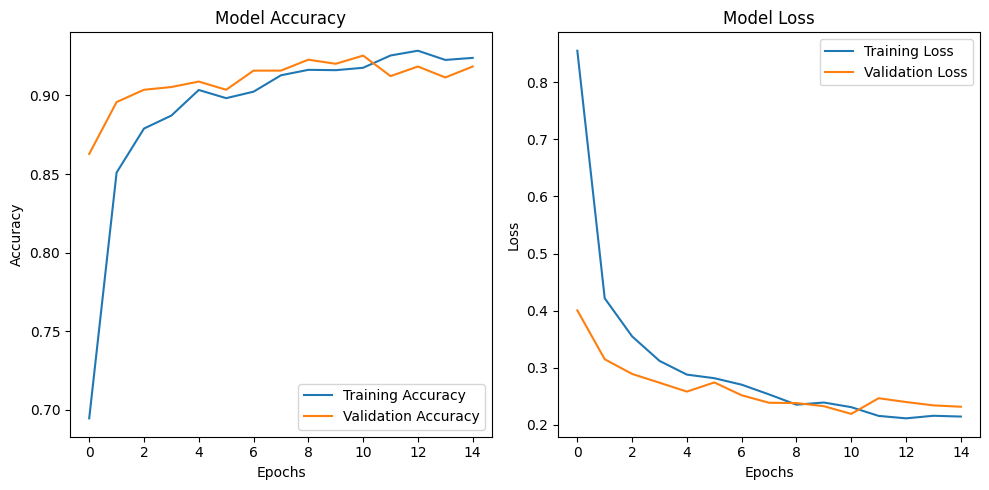

In [14]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

36/36 ━━━━━━━━━━━━━━━━━━━━ 8s 157ms/step
              precision    recall  f1-score   support

  biological       0.16      0.15      0.16       181
   cardboard       0.09      0.09      0.09       162
       glass       0.11      0.10      0.10       101
       metal       0.17      0.17      0.17       167
       paper       0.20      0.21      0.20       218
     plastic       0.16      0.16      0.16       174
       trash       0.15      0.14      0.15       148

    accuracy                           0.15      1151
   macro avg       0.15      0.15      0.15      1151
weighted avg       0.15      0.15      0.15      1151



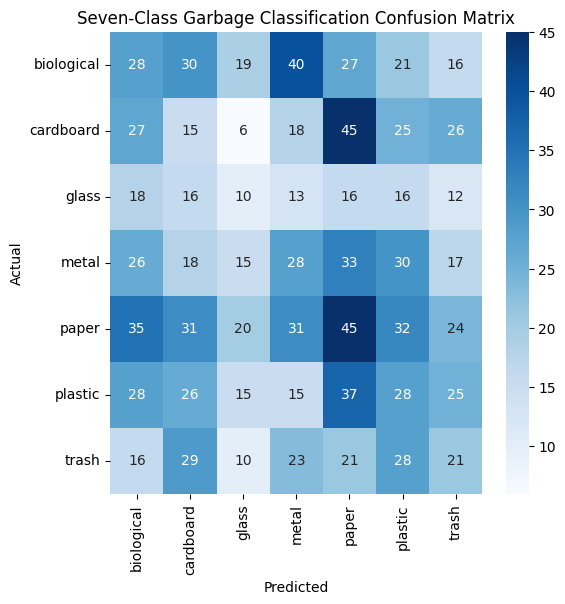

In [15]:
import seaborn as sns
from sklearn.metrics import confusion_matrix,classification_report
y_true=np.concatenate([
    labels.numpy() for images,labels in val_ds
])
y_prob=model.predict(val_ds,verbose=1)
y_pred=np.argmax(y_prob,axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))
cm=confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)
plt.figure(figsize=(6,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Seven-Class Garbage Classification Confusion Matrix")
plt.show()



In [16]:
import os
import numpy as np

SAVE_DIR="/content"
os.makedirs(SAVE_DIR,exist_ok=True)
model.save(os.path.join(SAVE_DIR,"garbage_classification_model.keras"))
np.save(os.path.join(SAVE_DIR,"class_names.npy"),np.array(class_names))
print("Model and class names Saved Successfully")

Model and class names Saved Successfully


In [17]:
import os
import zipfile

model_path = "/content/garbage_classification_model.keras"

print("File exists:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
print("Valid .keras ZIP file:", zipfile.is_zipfile(model_path))

File exists: True
File size: 9.29 MB
Valid .keras ZIP file: True


In [18]:
print(model.summary())
print(class_names)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,887 (8.72 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 17,936 (70.07 KB)

None
['biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [20]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf


# Define the preprocessing function that was used when building/training the model
def preprocess_input(x):
  return x / 127.5 - 1.0


# Pass the function to custom_objects so tf.keras can locate it
model = tf.keras.models.load_model(
    "/content/garbage_classification_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
)
print("Model Loaded Successfully")

class_names = np.load("/content/class_names.npy")
print("Class Names Loaded Successfully")

Model Loaded Successfully
Class Names Loaded Successfully


In [21]:
test_loss,test_accuracy=model.evaluate(val_ds)
print("Test Loss: ",test_loss)
print("Test Accuracy: ",test_accuracy*100,"%")

36/36 ━━━━━━━━━━━━━━━━━━━━ 8s 139ms/step - accuracy: 0.9253 - loss: 0.2191
Test Loss:  0.2191469669342041
Test Accuracy:  92.528235912323 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step


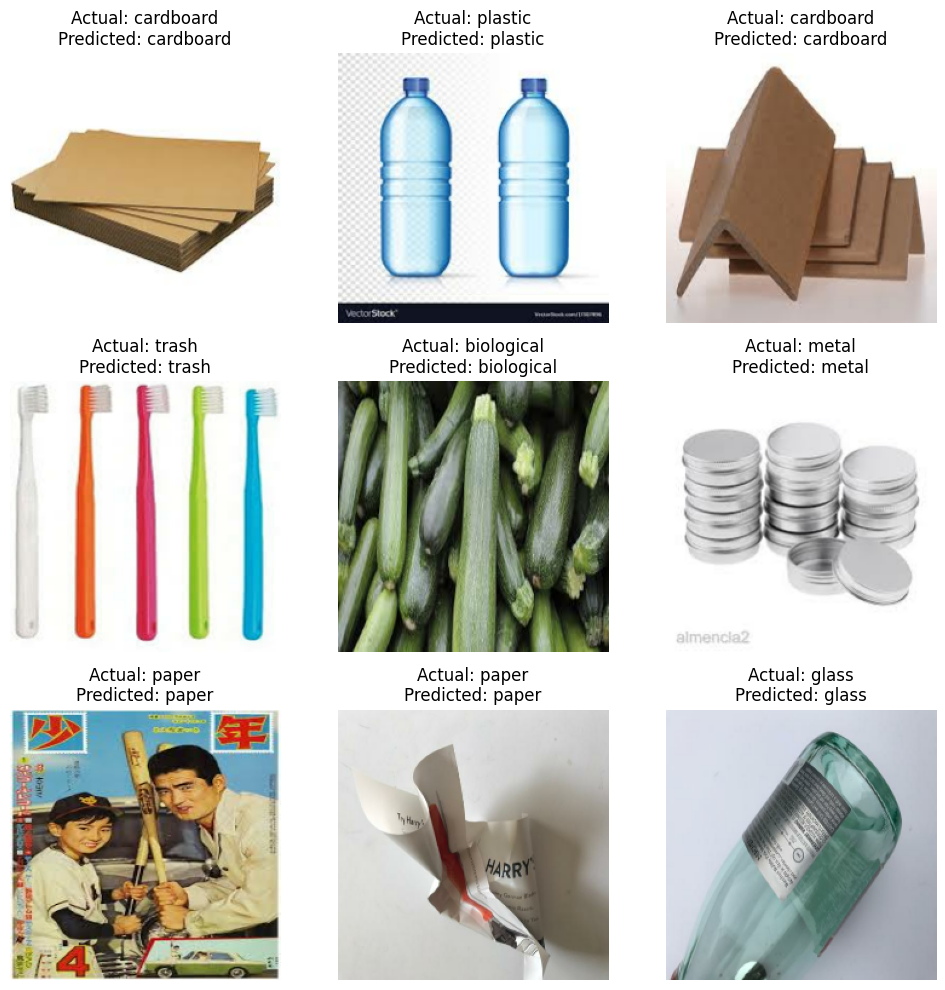

In [25]:
import numpy as np
import matplotlib.pyplot as plt

class_names= val_ds.class_names
for images,labels in val_ds.take(1):
  predictions=model.predict(images)
  plt.figure(figsize=(10,10))
  for i in range(min(9,len(images))):
    plt.subplot(3,3,i+1)
    actual=class_names[int(labels[i])]
    predicted=class_names[np.argmax(predictions[i])]
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [26]:
loss,accuracy=model.evaluate(val_ds)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy*100:.2f}%")

36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - accuracy: 0.9253 - loss: 0.2191
Validation Loss: 0.2191
Validation Accuracy: 92.53%


In [28]:
import numpy as np
from sklearn.metrics import classification_report
y_true=np.concatenate([
    labels.numpy() for images,labels in val_ds
])
y_pred=np.concatenate([
    np.argmax(model.predict(images),axis=1)
    for images,labels in val_ds
])
print(classification_report(y_true,y_pred,target_names=val_ds.class_names))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 